## Cài đặt dữ liệu
Thực hiện cài đặt dữ liệu từ Kaggle

In [86]:
# Load packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("darkgrid")

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Lasso

from sklearn.neighbors import KNeighborsClassifier

from sklearn.decomposition import PCA

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.cluster import KMeans
from sklearn.svm import LinearSVC

from sklearn.pipeline import make_pipeline

from sklearn import metrics
from sklearn.metrics import (
    accuracy_score,
    mean_squared_error,
    mean_absolute_percentage_error,
    confusion_matrix,
    make_scorer,
    precision_score,
    recall_score,
    RocCurveDisplay,
    roc_auc_score,
    r2_score, f1_score
)


In [4]:
df_all = pd.read_csv('D:/Project/SmartCampus/Document/hospital_readmissions.csv')
df_all['age'] = df_all['age'].str.replace('[','(',regex=False)
df_all.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   age                25000 non-null  object
 1   time_in_hospital   25000 non-null  int64 
 2   n_lab_procedures   25000 non-null  int64 
 3   n_procedures       25000 non-null  int64 
 4   n_medications      25000 non-null  int64 
 5   n_outpatient       25000 non-null  int64 
 6   n_inpatient        25000 non-null  int64 
 7   n_emergency        25000 non-null  int64 
 8   medical_specialty  25000 non-null  object
 9   diag_1             25000 non-null  object
 10  diag_2             25000 non-null  object
 11  diag_3             25000 non-null  object
 12  glucose_test       25000 non-null  object
 13  A1Ctest            25000 non-null  object
 14  change             25000 non-null  object
 15  diabetes_med       25000 non-null  object
 16  readmitted         25000 non-null  objec

## Khai phá dữ liệu

In [5]:
df_all.shape
df_all.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   age                25000 non-null  object
 1   time_in_hospital   25000 non-null  int64 
 2   n_lab_procedures   25000 non-null  int64 
 3   n_procedures       25000 non-null  int64 
 4   n_medications      25000 non-null  int64 
 5   n_outpatient       25000 non-null  int64 
 6   n_inpatient        25000 non-null  int64 
 7   n_emergency        25000 non-null  int64 
 8   medical_specialty  25000 non-null  object
 9   diag_1             25000 non-null  object
 10  diag_2             25000 non-null  object
 11  diag_3             25000 non-null  object
 12  glucose_test       25000 non-null  object
 13  A1Ctest            25000 non-null  object
 14  change             25000 non-null  object
 15  diabetes_med       25000 non-null  object
 16  readmitted         25000 non-null  objec

In [6]:
df_all.isnull().sum()

age                  0
time_in_hospital     0
n_lab_procedures     0
n_procedures         0
n_medications        0
n_outpatient         0
n_inpatient          0
n_emergency          0
medical_specialty    0
diag_1               0
diag_2               0
diag_3               0
glucose_test         0
A1Ctest              0
change               0
diabetes_med         0
readmitted           0
dtype: int64

In [7]:
cols = ['medical_specialty','diag_1','diag_2','diag_3']
for i in cols:
    print(i)
    print(df_all[i].unique())

medical_specialty
['Missing' 'Other' 'InternalMedicine' 'Family/GeneralPractice'
 'Cardiology' 'Surgery' 'Emergency/Trauma']
diag_1
['Circulatory' 'Other' 'Injury' 'Digestive' 'Respiratory' 'Diabetes'
 'Musculoskeletal' 'Missing']
diag_2
['Respiratory' 'Other' 'Circulatory' 'Injury' 'Diabetes' 'Digestive'
 'Musculoskeletal' 'Missing']
diag_3
['Other' 'Circulatory' 'Diabetes' 'Respiratory' 'Injury' 'Musculoskeletal'
 'Digestive' 'Missing']


In [8]:
df_all['diag_1'] = np.where(df_all['diag_1'] == 'Other', 
                            np.where(df_all['diag_2'] == 'Other',
                                     df_all['diag_3'],
                                     df_all['diag_2']
                                    ), 
                            df_all['diag_1'])
df_all['diag_1'].value_counts(normalize=True)

diag_1
Circulatory        0.39128
Respiratory        0.17760
Diabetes           0.12628
Digestive          0.10988
Injury             0.07576
Other              0.06272
Musculoskeletal    0.05600
Missing            0.00048
Name: proportion, dtype: float64

## Chuyển đổi dữ liệu

In [9]:
textCols = ['glucose_test','A1Ctest','change','diabetes_med','readmitted']
for i in textCols:
    print(i)
    print(df_all[i].unique())

glucose_test
['no' 'normal' 'high']
A1Ctest
['no' 'normal' 'high']
change
['no' 'yes']
diabetes_med
['yes' 'no']
readmitted
['no' 'yes']


In [10]:
binaryCols = ['change','diabetes_med','readmitted']
for i in binaryCols:
    df_all[i] = df_all[i].apply(lambda x: 0 if x == 'no' else 1)

In [11]:
noNormalHighCols = ['glucose_test','A1Ctest']
le = LabelEncoder()
for i in noNormalHighCols:
    #df_all[i] = le.fit_transform(df_all[i])
    df_all[i+'_ind'] = df_all[i].apply(lambda x: 0 if x == 'no' else 1 if x == 'normal' else 2)

df_all['age_t'] = le.fit_transform(df_all['age'])

In [12]:
df_all

,age,time_in_hospital,n_lab_procedures,n_procedures,n_medications,n_outpatient,n_inpatient,n_emergency,medical_specialty,diag_1,diag_2,diag_3,glucose_test,A1Ctest,change,diabetes_med,readmitted,glucose_test_ind,A1Ctest_ind,age_t
0,(70-80),8,72,1,18,2,0,0,Missing,Circulatory,Respiratory,Other,no,no,0,1,0,0,0,3
1,(70-80),3,34,2,13,0,0,0,Other,Other,Other,Other,no,no,0,1,0,0,0,3
2,(50-60),5,45,0,18,0,0,0,Missing,Circulatory,Circulatory,Circulatory,no,no,1,1,1,0,0,1
3,(70-80),2,36,0,12,1,0,0,Missing,Circulatory,Other,Diabetes,no,no,1,1,1,0,0,3
4,(60-70),1,42,0,7,0,0,0,InternalMedicine,Circulatory,Circulatory,Respiratory,no,no,0,1,0,0,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24995,(80-90),14,77,1,30,0,0,0,Missing,Circulatory,Other,Circulatory,no,normal,0,0,1,0,1,4
24996,(80-90),2,66,0,24,0,0,0,Missing,Digestive,Injury,Other,no,high,1,1,1,0,2,4
24997,(70-80),5,12,0,6,0,1,0,Missing,Other,Other,Other,normal,no,0,0,1,1,0,3
24998,(70-80),2,61,3,15,0,0,0,Family/GeneralPractice,Respiratory,Diabetes,Other,no,no,1,1,0,0,0,3


In [13]:
df_all.dtypes

age                  object
time_in_hospital      int64
n_lab_procedures      int64
n_procedures          int64
n_medications         int64
n_outpatient          int64
n_inpatient           int64
n_emergency           int64
medical_specialty    object
diag_1               object
diag_2               object
diag_3               object
glucose_test         object
A1Ctest              object
change                int64
diabetes_med          int64
readmitted            int64
glucose_test_ind      int64
A1Ctest_ind           int64
age_t                 int64
dtype: object

In [14]:
#Add diabetes indicator (i.e. if any of diagnoses are diabetes 1, else 0)
diagCols = ['diag_1','diag_2','diag_3']
diag = 'Diabetes'

df_all['Diabetes_ind'] = (df_all['diag_1'].str.contains(diag) | df_all['diag_2'].str.contains(diag) | df_all['diag_3'].str.contains(diag)) * 1


In [15]:
df_all[df_all['Diabetes_ind'] == 1].head()

,age,time_in_hospital,n_lab_procedures,n_procedures,n_medications,n_outpatient,n_inpatient,n_emergency,medical_specialty,diag_1,...,diag_3,glucose_test,A1Ctest,change,diabetes_med,readmitted,glucose_test_ind,A1Ctest_ind,age_t,Diabetes_ind
3,(70-80),2,36,0,12,1,0,0,Missing,Circulatory,...,Diabetes,no,no,1,1,1,0,0,3,1
12,(70-80),8,67,0,21,0,0,0,Other,Diabetes,...,Other,no,normal,0,1,0,0,1,3,1
14,(80-90),2,73,1,26,0,0,0,InternalMedicine,Circulatory,...,Diabetes,no,no,0,1,0,0,0,4,1
16,(70-80),3,52,0,10,0,0,0,Other,Circulatory,...,Diabetes,no,no,0,1,1,0,0,3,1
18,(40-50),7,72,0,13,0,0,0,InternalMedicine,Diabetes,...,Other,no,high,0,1,1,0,2,0,1


In [16]:
df_all['readmitted'].value_counts(normalize=True)

readmitted
0    0.52984
1    0.47016
Name: proportion, dtype: float64

In [17]:
df_all[['Diabetes_ind','readmitted']].value_counts(normalize=True)

Diabetes_ind  readmitted
0             0             0.34188
              1             0.30660
1             0             0.18796
              1             0.16356
Name: proportion, dtype: float64

In [ ]:
#Binning
visits = pd.qcut(df_all['n_lab_procedures'],[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
                      labels=['1st Decile', '2nd Decile','3rd Decile','4th Decile',
                              '5th Decile','6th Decile','7th Decile','8th Decile',
                              '9th Decile','10th Decile'])
df_all['n_lab_procedures_bucket'] = visits

# CHi thuốc thành 5 nhóm
medications = pd.qcut(df_all['n_medications'],[0, 0.2, 0.4, 0.6, 0.8, 1.0],
                      labels=['Low', 'Low Moderate','Moderate', 
                              'High', 'Very High'])
df_all['n_medications_bucket'] = medications

#n_outpatient bucketing
visits = pd.cut(df_all['n_outpatient'],bins = [-0.001, 0, 1, 10, 25],
                      labels=['None', 'One','Up to 10', 
                              'Up to 25'])
df_all['n_outpatient_bucket'] = visits

#n_emergency bucketing
visits = pd.cut(df_all['n_emergency'],bins = [-0.001, 0, 1, 10, 100],
                      labels=['None', 'One','Up to 10', 
                              '>10'])
df_all['n_emergency_bucket'] = visits

#n_inpatient bucketing
visits = pd.cut(df_all['n_inpatient'],bins = [-0.001, 0, 1, 5, 10, 15],
                      labels=['None', 'One','Up to 5','Up to 10', 
                              '>10'])
df_all['n_inpatient_bucket'] = visits


C:\Users\skyge\AppData\Local\Temp\ipykernel_5028\4095979310.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  chart.set_xticklabels(chart.get_xticklabels(), rotation=45, horizontalalignment='right')


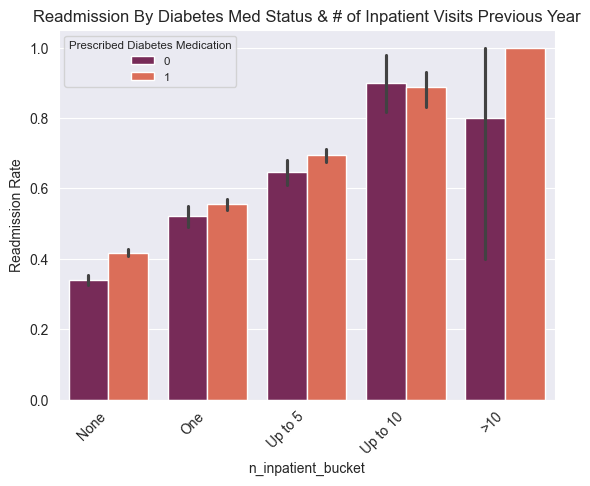

C:\Users\skyge\AppData\Local\Temp\ipykernel_5028\4095979310.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  chart.set_xticklabels(chart.get_xticklabels(), rotation=45, horizontalalignment='right')


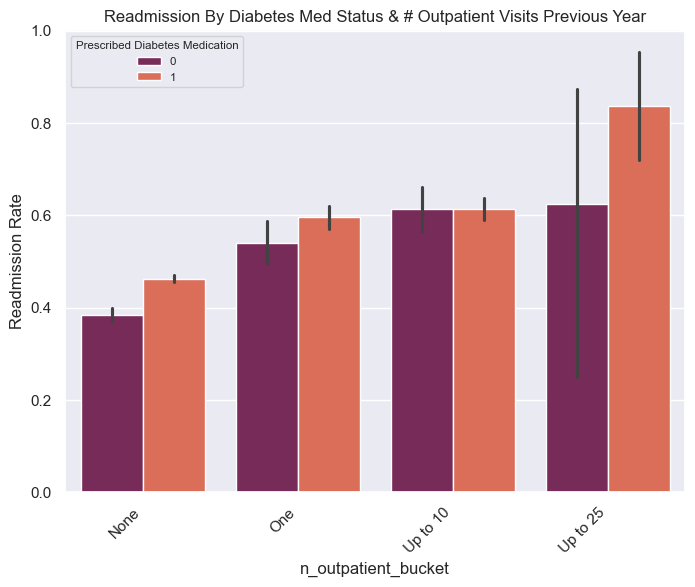

C:\Users\skyge\AppData\Local\Temp\ipykernel_5028\4095979310.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  chart.set_xticklabels(chart.get_xticklabels(), rotation=45, horizontalalignment='right')


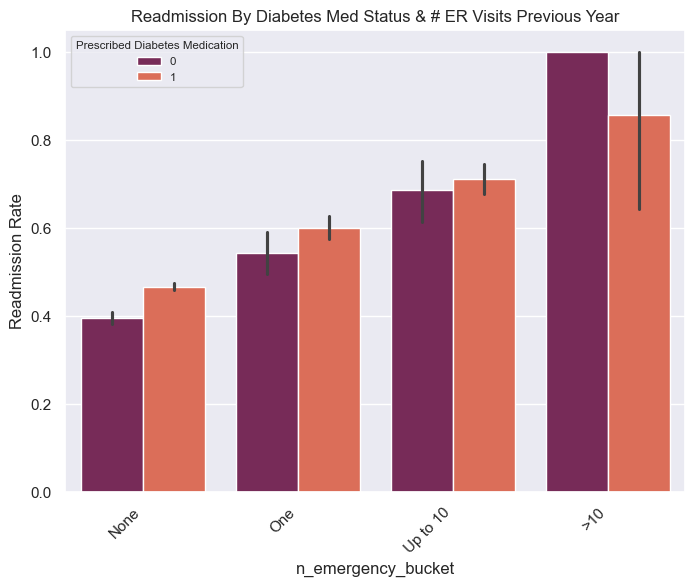

C:\Users\skyge\AppData\Local\Temp\ipykernel_5028\4095979310.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  chart.set_xticklabels(chart.get_xticklabels(), rotation=45, horizontalalignment='right')


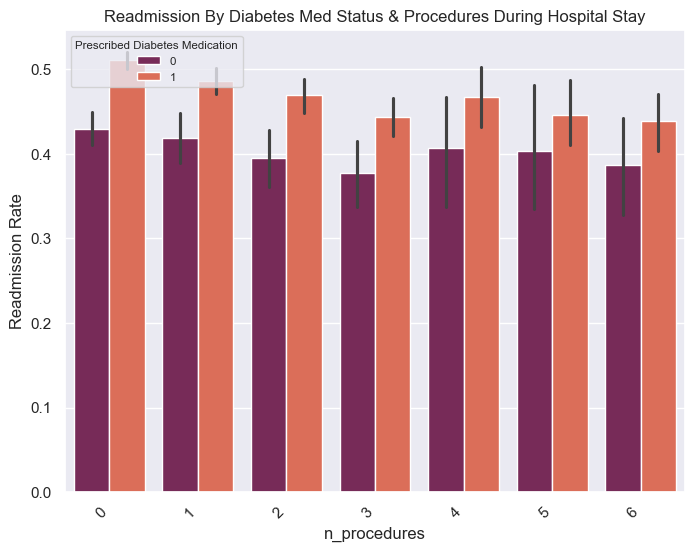

C:\Users\skyge\AppData\Local\Temp\ipykernel_5028\4095979310.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  chart.set_xticklabels(chart.get_xticklabels(), rotation=45, horizontalalignment='right')


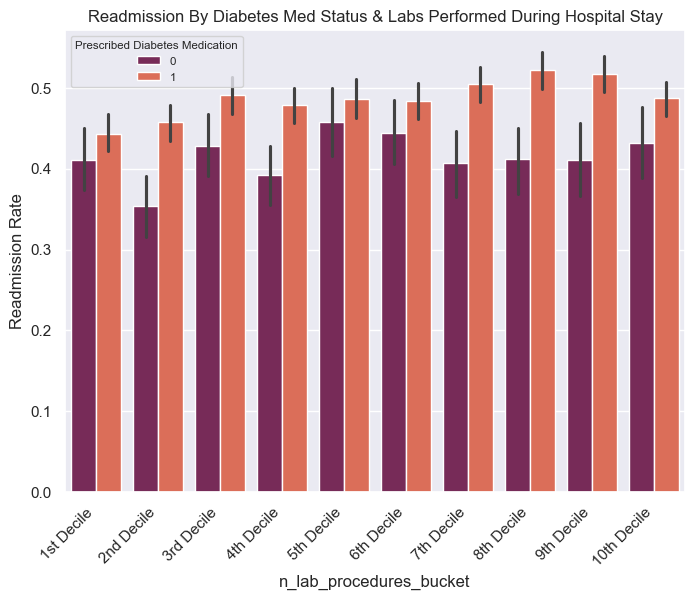

C:\Users\skyge\AppData\Local\Temp\ipykernel_5028\4095979310.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  chart.set_xticklabels(chart.get_xticklabels(), rotation=45, horizontalalignment='right')


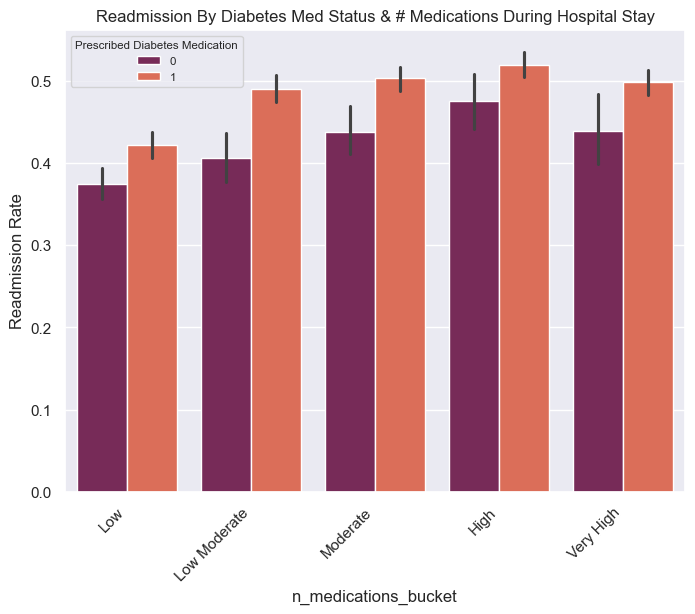

In [19]:
cols = {
        'n_inpatient_bucket':'# of Inpatient Visits Previous Year',
        "n_outpatient_bucket":'# Outpatient Visits Previous Year',
        "n_emergency_bucket":'# ER Visits Previous Year',
        "n_procedures":'Procedures During Hospital Stay',
        "n_lab_procedures_bucket":'Labs Performed During Hospital Stay',
        "n_medications_bucket":'# Medications During Hospital Stay'
        }
df_chart = df_all.sort_values('age')

for i in cols.keys():
    #df_chart.head()
    chart = sns.barplot(data=df_chart,x=i,y="readmitted",hue='diabetes_med',palette = 'rocket',errorbar=('ci', 95))
    chart.set_xticklabels(chart.get_xticklabels(), rotation=45, horizontalalignment='right')
    #chart.set(ylim=(0.3, 1.2))
    sns.set(rc={'figure.figsize':(8,6)})
    plt.legend(loc='upper left',title='Prescribed Diabetes Medication',fontsize='x-small',title_fontsize='x-small')
    plt.ylabel('Readmission Rate')
    plt.title("Readmission By Diabetes Med Status & "+cols[i])
    plt.show()

In [20]:
from scipy.stats import ttest_ind

for i in df_all['age'].sort_values().unique(): #Age groupings
    #define samples
    nonDiabetics = df_all[(df_all['Diabetes_ind']==0) & (df_all['age'] == i)]
    diabetics = df_all[(df_all['Diabetes_ind']==1) & (df_all['age'] == i)]

    print('T-test results in group: ',i)
    #perform independent two sample t-test
    print('Non-Diabetics Avg Readmittance: ',"{:.2f}%".format(np.mean(nonDiabetics['readmitted'])*100))
    print('Diabetics Avg Readmittance: ',"{:.2f}%".format(np.mean(diabetics['readmitted'])*100))
    print("T-Statistic {:.2f}:".format(ttest_ind(nonDiabetics['readmitted'], diabetics['readmitted']).statistic))
    print("P-Value {:.2f}%:".format(ttest_ind(nonDiabetics['readmitted'], diabetics['readmitted']).pvalue*100))
    print('')

T-test results in group:  (40-50)
Non-Diabetics Avg Readmittance:  43.53%
Diabetics Avg Readmittance:  45.40%
T-Statistic -0.94:
P-Value 34.52%:

T-test results in group:  (50-60)
Non-Diabetics Avg Readmittance:  44.58%
Diabetics Avg Readmittance:  43.62%
T-Statistic 0.64:
P-Value 52.30%:

T-test results in group:  (60-70)
Non-Diabetics Avg Readmittance:  47.69%
Diabetics Avg Readmittance:  45.31%
T-Statistic 1.75:
P-Value 7.97%:

T-test results in group:  (70-80)
Non-Diabetics Avg Readmittance:  49.00%
Diabetics Avg Readmittance:  48.33%
T-Statistic 0.52:
P-Value 60.54%:

T-test results in group:  (80-90)
Non-Diabetics Avg Readmittance:  48.70%
Diabetics Avg Readmittance:  52.20%
T-Statistic -2.04:
P-Value 4.10%:

T-test results in group:  (90-100)
Non-Diabetics Avg Readmittance:  41.73%
Diabetics Avg Readmittance:  43.41%
T-Statistic -0.40:
P-Value 68.98%:



In [21]:
for i in df_all['age'].sort_values().unique(): #Age groupings
    #define samples
    noMeds = df_all[(df_all['diabetes_med']==0) & (df_all['age'] == i)]
    meds = df_all[(df_all['diabetes_med']==1) & (df_all['age'] == i)]

    print('T-test results in group: ',i)
    #perform independent two sample t-test
    print('No Diabetes Meds: ',"{:.2f}%".format(np.mean(noMeds['readmitted'])*100))
    print('Yes Diabetes Meds: ',"{:.2f}%".format(np.mean(meds['readmitted'])*100))
    print("T-Statistic {:.2f}:".format(ttest_ind(noMeds['readmitted'], meds['readmitted']).statistic))
    print("P-Value {:.2f}%:".format(ttest_ind(noMeds['readmitted'], meds['readmitted']).pvalue*100))
    print('')

T-test results in group:  (40-50)
No Diabetes Meds:  38.59%
Yes Diabetes Meds:  46.33%
T-Statistic -3.33:
P-Value 0.09%:

T-test results in group:  (50-60)
No Diabetes Meds:  40.19%
Yes Diabetes Meds:  45.25%
T-Statistic -2.80:
P-Value 0.52%:

T-test results in group:  (60-70)
No Diabetes Meds:  41.84%
Yes Diabetes Meds:  48.23%
T-Statistic -4.06:
P-Value 0.00%:

T-test results in group:  (70-80)
No Diabetes Meds:  42.31%
Yes Diabetes Meds:  50.77%
T-Statistic -5.94:
P-Value 0.00%:

T-test results in group:  (80-90)
No Diabetes Meds:  42.67%
Yes Diabetes Meds:  51.85%
T-Statistic -5.35:
P-Value 0.00%:

T-test results in group:  (90-100)
No Diabetes Meds:  37.44%
Yes Diabetes Meds:  44.07%
T-Statistic -1.67:
P-Value 9.50%:



## Tiền xử lý Dữ liệu

In [ ]:
# Lấy các cột dữ liệu dạng số
quantCols = df_all.select_dtypes(
    include=[int, float]
).columns

# Tách đặc trưng đầu vào
X = df_all[quantCols].drop(
    columns=['readmitted']
)

# Tách biến mục tiêu
y = df_all['readmitted']
print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (25000, 13)
y shape: (25000,)
readmitted in X: False


In [28]:
for i in transformCols:
    df_log[i].replace([np.inf, -np.inf], np.nan, inplace=True)
    df_log[i] = df_log[i].fillna(df_log[i].mean())

np.isinf(df_log).sum()

C:\Users\skyge\AppData\Local\Temp\ipykernel_5028\499657902.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_log[i].replace([np.inf, -np.inf], np.nan, inplace=True)


time_in_hospital    0
n_lab_procedures    0
n_procedures        0
n_medications       0
n_outpatient        0
n_inpatient         0
n_emergency         0
change              0
diabetes_med        0
readmitted          0
glucose_test_ind    0
A1Ctest_ind         0
age_t               0
Diabetes_ind        0
dtype: int64

In [101]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.275,
    random_state=123,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (18124, 13)
X_test: (6876, 13)
y_train: (18124,)
y_test: (6876,)


In [102]:
X_train_log = X_train.copy()
X_test_log = X_test.copy()

for feature in transformCols:
    X_train_log[feature] = np.log1p(
        X_train[feature]
    )

    X_test_log[feature] = np.log1p(
        X_test[feature]
    )

In [105]:
scaler = StandardScaler()
pca = PCA(n_components=0.95)

# Chỉ học tham số từ tập Train
X_train_scaled = scaler.fit_transform(
    X_train_log
)

X_train_pca = pca.fit_transform(
    X_train_scaled
)

# Tập Test chỉ sử dụng tham số đã học
X_test_scaled = scaler.transform(
    X_test_log
)

X_test_pca = pca.transform(
    X_test_scaled
)

In [106]:
pca_columns = [
    f'PC{i+1}'
    for i in range(X_train_pca.shape[1])
]

X_train_processed = pd.DataFrame(
    X_train_pca,
    columns=pca_columns,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_pca,
    columns=pca_columns,
    index=X_test.index
)

<Axes: title={'center': 'Ma trận tương quan của các thuộc tính'}>

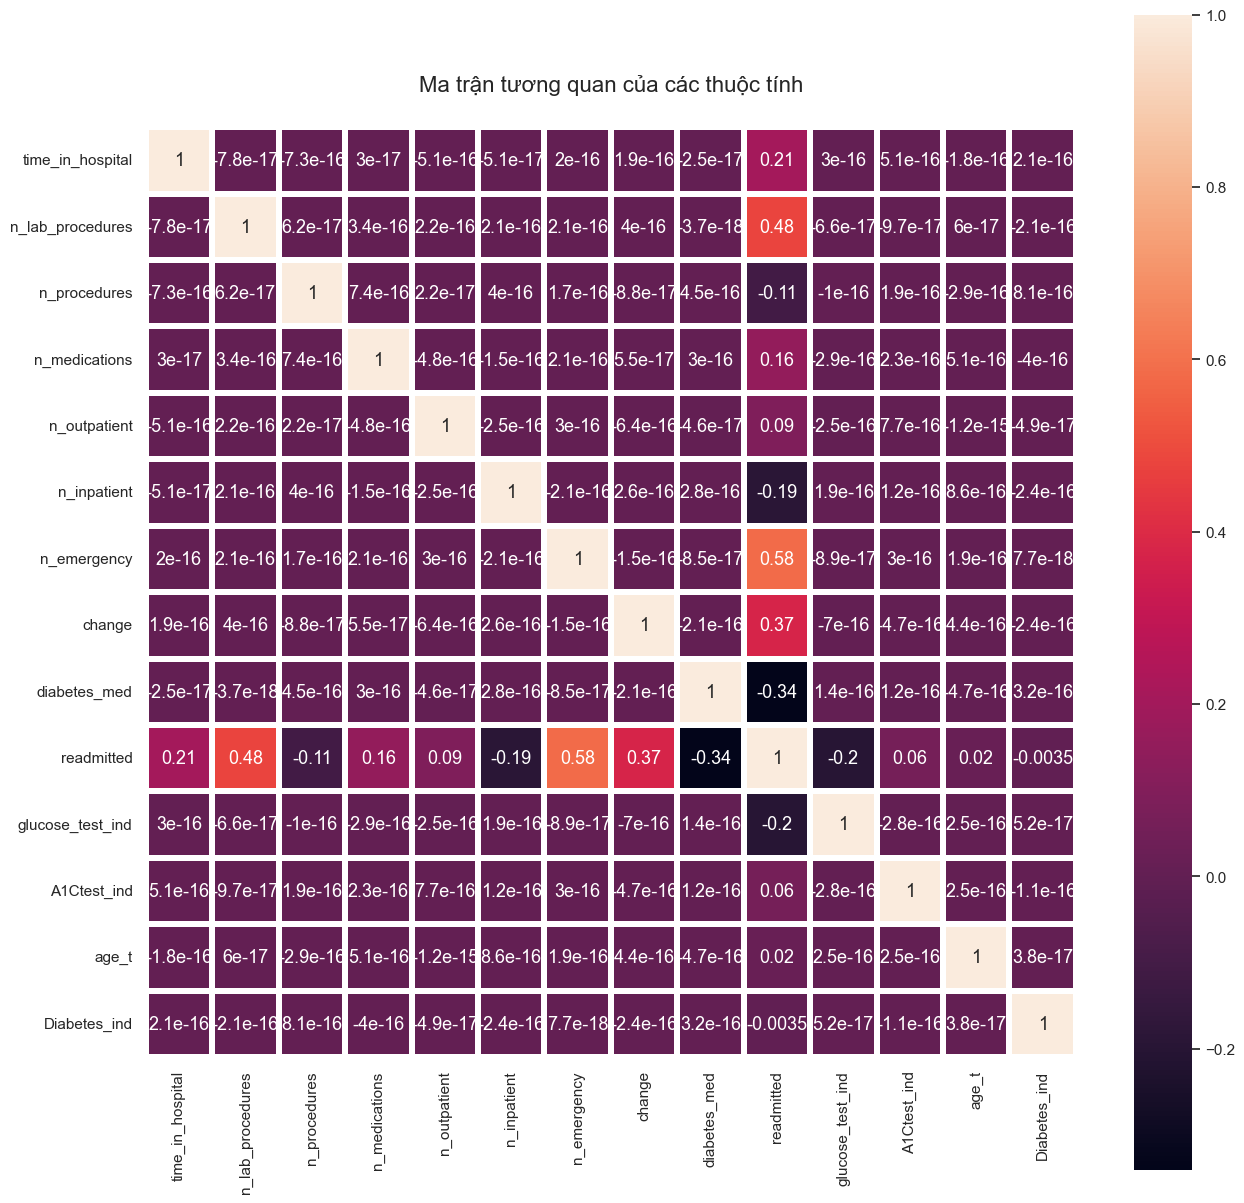

In [32]:
corr_matrix(df_processed, 15, 15, 'Ma trận tương quan của các thuộc tính')

In [99]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.275,
    random_state=123,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (18124, 13)
X_test: (6876, 13)
y_train: (18124,)
y_test: (6876,)


## Chạy với RandomForest

In [109]:
params = {
    "n_estimators": 97,  # Number of trees in the forest
    "max_depth": 10,  # Max depth of the tree
    "min_samples_split": 3,  # Min number of samples required to split a node
    "min_samples_leaf": 1,  # Min number of samples required at a leaf node
    "ccp_alpha": 0,  # Cost complexity parameter for pruning
    "random_state": 123,
}

rf = RandomForestClassifier(**params)

rf = rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

In [110]:
print('Training Set:', rf.score(X_train,y_train))
print('Test Set:', rf.score(X_test,y_test))

# Calculate the accuracy, precision, and recall scores
print("Accuracy:", "{:.2f}%".format(accuracy_score(y_test, y_pred)*100))
print("Precision:", "{:.2f}%".format(precision_score(y_test, y_pred)*100))
print("Recall:", "{:.2f}%".format(recall_score(y_test, y_pred)*100))
print("Area Under the Curve:", "{:.2f}%".format(roc_auc_score(y_test, y_pred)*100))


Training Set: 0.6864378724343412
Test Set: 0.6092204770215242
Accuracy: 60.92%
Precision: 60.89%
Recall: 47.23%
Area Under the Curve: 60.15%


In [111]:
scores = cross_val_score(
    rf,
    X_train,
    y_train,
    cv=5,
    scoring='f1',
    verbose=1
)

print("Cross-validation scores:", scores)
print("Mean F1:", scores.mean())
print("Std F1:", scores.std())

Cross-validation scores: [0.5540673  0.53471989 0.51644415 0.5547541  0.53520187]
Mean F1: 0.5390374625632482
Std F1: 0.014259869146042659


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    3.0s finished


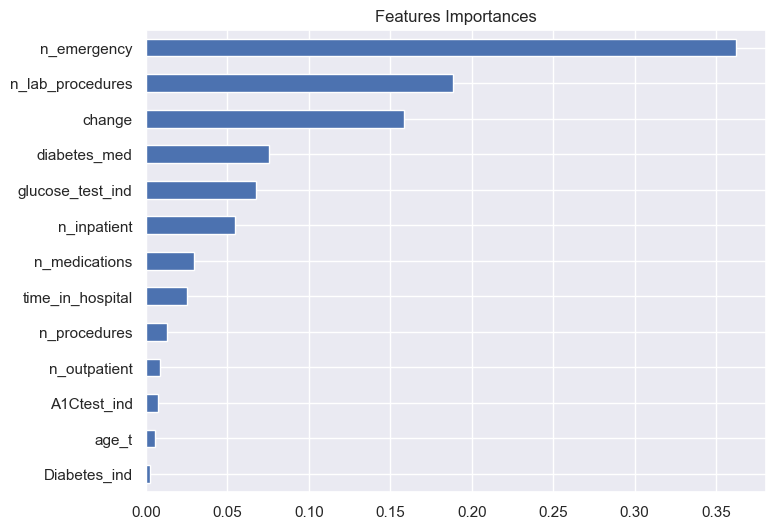

In [74]:
importances_sorted = pd.Series(
    data=rf.feature_importances_, index=X_train.columns
).sort_values()

# Plot a horizontal barplot of importances_sorted
importances_sorted.plot(kind="barh")
plt.title("Features Importances")
plt.show()

In [75]:
rs_param_grid = {
    "n_estimators": list((range(20, 200))),
    "max_depth": list((range(3, 15))),
    "min_samples_split": list((range(2, 5))),
    "min_samples_leaf": list((range(1, 5))),
    "ccp_alpha": [0, 0.001, 0.01, 0.1],
}
rf = RandomForestClassifier(random_state=42)
rf_rs = RandomizedSearchCV(
    estimator=rf,
    param_distributions=rs_param_grid,
    cv=3,  # Number of folds
    n_iter=10,  # Number of parameter candidate settings to sample
    verbose=1,  # The higher this is, the more messages are outputed
    scoring="accuracy",  # Metric to evaluate performance
    random_state=123
)
rf_rs.fit(X_train, y_train)

# Print the best parameters and highest accuracy
print("Best parameters found: ", rf_rs.best_params_)
print("Best performance: ", rf_rs.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters found:  {'n_estimators': 97, 'min_samples_split': 3, 'min_samples_leaf': 1, 'max_depth': 10, 'ccp_alpha': 0}
Best performance:  0.9982499899907494


## Trying out a KNNClassifier

In [112]:
params = {
    "n_neighbors": 20
}

knn1 = KNeighborsClassifier(
    **params
)
knn1.fit(X_train, y_train)
y_pred = knn1.predict(X_test)
print(type(knn1))

<class 'sklearn.neighbors._classification.KNeighborsClassifier'>


Accuracy: 56.09%
Precision: 55.36%
Recall: 34.18%
Area Under the Curve: 54.86%


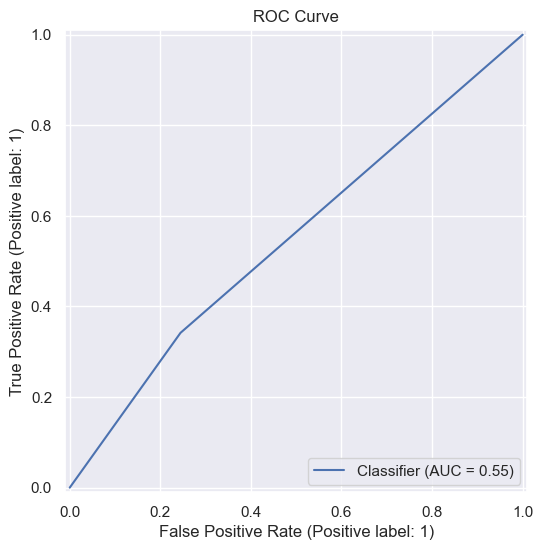

In [116]:
print("Accuracy:", "{:.2f}%".format(accuracy_score(y_test, y_pred)*100))
print("Precision:", "{:.2f}%".format(precision_score(y_test, y_pred)*100))
print("Recall:", "{:.2f}%".format(recall_score(y_test, y_pred)*100))
print("Area Under the Curve:", "{:.2f}%".format(roc_auc_score(y_test, y_pred)*100))
RocCurveDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title("ROC Curve")
plt.show()

In [114]:
scores = cross_val_score(
    knn1,
    X_train,
    y_train,
    cv=5,
    scoring='f1',
    verbose=1
)

print("Cross-validation scores:", scores)
print("Mean F1:", scores.mean())
print("Std F1:", scores.std())

Cross-validation scores: [0.43493889 0.42584435 0.42303513 0.42682048 0.42983752]
Mean F1: 0.42809527318829044
Std F1: 0.004053821775947901


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.6s finished


## Logistic Regression

In [107]:
params = {
    "penalty": "l2",  # Norm of the penalty: 'l1', 'l2', 'elasticnet', 'none'
    #"C": 1,  # Inverse of regularization strength, a positive float
    "random_state": 123,
}

clf = LogisticRegression(**params)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
df_coef = pd.DataFrame({
    'feature': X_train.columns,
    'coef': clf.coef_[0]
})

df_coef['odds_ratio'] = np.exp(
    df_coef['coef']
)

df_coef = df_coef.sort_values(
    by='coef'
)

display(df_coef)

c:\Users\skyge\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\skyge\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
 

,feature,coef,odds_ratio
2,n_procedures,-0.043338,0.957587
10,A1Ctest_ind,-0.037344,0.963345
1,n_lab_procedures,0.002738,1.002742
3,n_medications,0.003174,1.003179
0,time_in_hospital,0.008099,1.008132
9,glucose_test_ind,0.030406,1.030873
12,Diabetes_ind,0.038380,1.039126
11,age_t,0.054162,1.055656
7,change,0.119259,1.126662
4,n_outpatient,0.136858,1.146665


In [83]:
print('Training Set:', clf.score(X_train,y_train))
print('Test Set:', clf.score(X_test,y_test))


'''
Logistic regression models tend to overfit the data, particularly in high-dimensional settings 
(which is the clever way of saying cases with lots of predictors). For this reason, it’s common to use some 
kind of regularisation method to prevent the model from fitting too closely to the training data.

In this case, I just did a small amout of dimensionality reduction.
'''

Training Set: 0.8668616199514456
Test Set: 0.868237347294939


'\nLogistic regression models tend to overfit the data, particularly in high-dimensional settings \n(which is the clever way of saying cases with lots of predictors). For this reason, it’s common to use some \nkind of regularisation method to prevent the model from fitting too closely to the training data.\n\nIn this case, I just did a small amout of dimensionality reduction.\n'

In [87]:
print("Accuracy:", "{:.2f}%".format(accuracy_score(y_test, y_pred)*100))
print("Precision:", "{:.2f}%".format(precision_score(y_test, y_pred)*100))
print("Recall:", "{:.2f}%".format(recall_score(y_test, y_pred)*100))
print("F1:", "{:.2f}%".format(f1_score(y_test, y_pred)*100))
print("Area Under the Curve:", "{:.2f}%".format(roc_auc_score(y_test, y_pred)*100))


Accuracy: 86.82%
Precision: 85.66%
Recall: 86.19%
F1: 85.92%
Area Under the Curve: 86.78%


Text(0.5, 33.249999999999986, 'Predicted label')

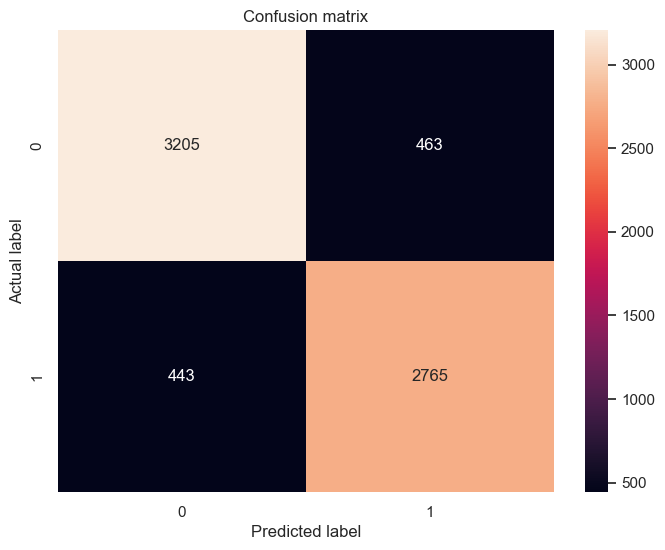

In [88]:
cnf_matrix = confusion_matrix(y_test, y_pred)

# Plot a labeled confusion matrix with Seaborn
sns.heatmap(cnf_matrix, annot=True, fmt="g")
plt.title("Confusion matrix")
plt.ylabel("Actual label")
plt.xlabel("Predicted label")

## Kiểm thử với LazyPredict

In [66]:
!pip install lazypredict
!pip install optuna


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



   -------------------- ------------------- 1/2 [optuna]
   -------------------- ------------------- 1/2 [optuna]
   -------------------- ------------------- 1/2 [optuna]
   -------------------- ------------------- 1/2 [optuna]
   -------------------- ------------------- 1/2 [optuna]
   -------------------- ------------------- 1/2 [optuna]
   -------------------- ------------------- 1/2 [optuna]
   -------------------- ------------------- 1/2 [optuna]
   -------------------- ------------------- 1/2 [optuna]
   -------------------- ------------------- 1/2 [optuna]
   -------------------- ------------------- 1/2 [optuna]
   -------------------- ------------------- 1/2 [optuna]
   -------------------- ------------------- 1/2 [optuna]
   -------------------- ------------------- 1/2 [optuna]
   -------------------- ------------------- 1/2 [optuna]
   -------------------- ------------------- 1/2 [optuna]
   -------------------- ------------------- 1/2 [optuna]
   -------------------- ------


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [117]:
from lazypredict.Supervised import LazyClassifier, LazyRegressor
from sklearn.metrics import cohen_kappa_score

In [118]:
clf = LazyClassifier(verbose=0,
                    ignore_warnings=True,
                    custom_metric=cohen_kappa_score,
                    predictions=False,
                    random_state=42,
                    classifiers = "all"
                    )

models_class, predictions_class = clf.fit(X_train , X_test , y_train , y_test)
models_class.sort_values(by='Accuracy', ascending=False,)

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,cohen_kappa_score,Time Taken
Model,,,,,,,,
SVC,0.612565,0.603455,0.636839,0.602771,0.614282,0.612565,0.210158,19.547891
AdaBoostClassifier,0.606603,0.597323,0.628948,0.596325,0.607956,0.606603,0.197761,0.415953
LogisticRegression,0.604567,0.592738,0.626135,0.587549,0.609924,0.604567,0.189423,0.037859
LinearSVC,0.602821,0.590221,0.624997,0.583340,0.609609,0.602821,0.184570,0.040810
CalibratedClassifierCV,0.602821,0.591039,0.625087,0.585885,0.607773,0.602821,0.185933,0.109412
LGBMClassifier,0.602094,0.595662,0.637918,0.597214,0.600925,0.602094,0.193261,0.117136
LinearDiscriminantAnalysis,0.601222,0.588328,0.623172,0.580717,0.608389,0.601222,0.180805,0.041325
RidgeClassifierCV,0.601076,0.588174,0.623173,0.580535,0.608234,0.601076,0.180491,0.041748
RidgeClassifier,0.601076,0.588174,0.623172,0.580535,0.608234,0.601076,0.180491,0.045579
